In [1]:
%pip install opencv-python numpy


[notice] A new release of pip is available: 23.2.1 -> 23.3.1
[notice] To update, run: python3.10 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


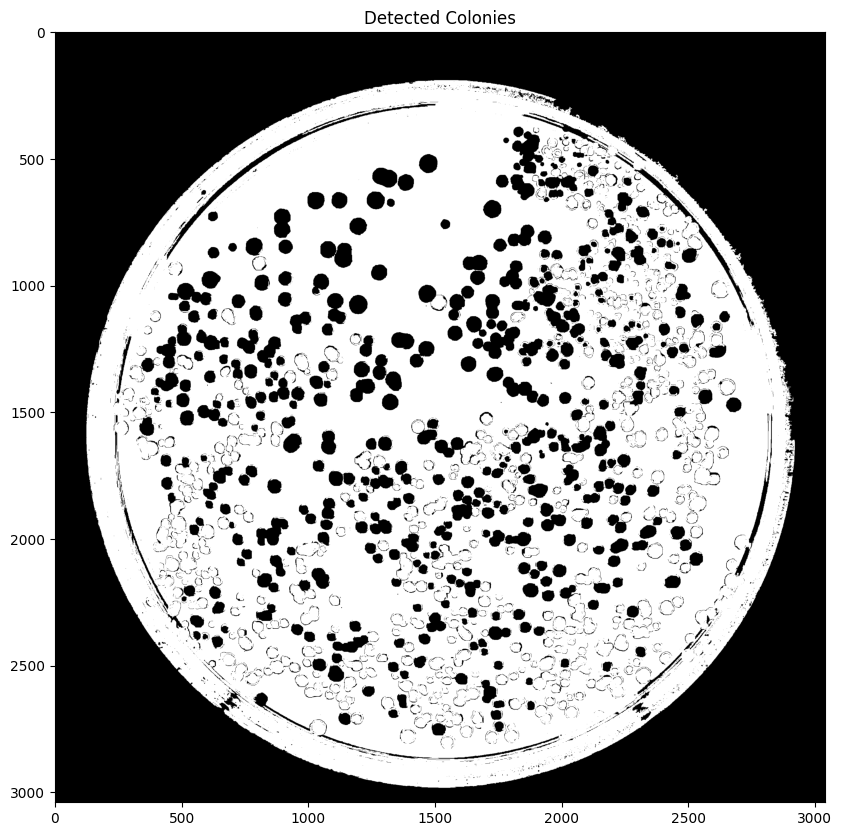

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


def count_colonies(image_path, debug=False):
    # Load the image
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if debug:
        plt.figure(figsize=(10, 10))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title("Grayscale Image")
        plt.show()

    height, width = img.shape

    # Use Gaussian blur to reduce noise and improve circle detection
    blurred = cv2.GaussianBlur(
        img,
        (1, 1),
        0,
    )
    if debug:
        plt.figure(figsize=(10, 10))
        plt.imshow(blurred, cmap="gray")
        plt.title("Blurred Image")
        plt.show()

    # Hough Circle detection
    outer_circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=6,
        minDist=30,
        param1=150,
        param2=10,
        # Circle should be large, but not larger than the image.
        minRadius=round(max(height, width) / 3),
        maxRadius=round(max(height, width) / 2),
    )

    if outer_circles is not None:
        # Convert circles to expected format
        outer_circles = np.uint16(np.around(outer_circles))

        # Create a black mask
        mask = np.zeros_like(img)

        # Get the (x, y) coordinate and the radius of the circle
        x, y, r = outer_circles[0][0]
        # r = r - 10  # Subtracting a value to remove the plastic border

        # Draw the circle in the mask
        cv2.circle(mask, (x, y), r, (255, 255, 255), -1)

        # Bitwise the image with mask
        result = cv2.bitwise_and(blurred, blurred, mask=mask)

        blurred = result

    if debug:
        plt.figure(figsize=(10, 10))
        plt.imshow(blurred, cmap="gray")
        plt.title("Cut out image")
        plt.show()

    center_x, center_y = width // 2, height // 2
    seed_point = (center_x, center_y)

    # Define the lower and upper thresholds for grayscale similarity
    # Adjust these values based on your requirements
    lower_threshold = 5  # Lower bound for grayscale value
    upper_threshold = 5  # Upper bound for grayscale value

    # Create a mask for floodFill
    mask = np.zeros((height + 2, width + 2), np.uint8)

    # Apply the floodFill
    cv2.floodFill(
        blurred,
        mask,
        seed_point,
        newVal=255,
        loDiff=lower_threshold,
        upDiff=upper_threshold,
        flags=cv2.FLOODFILL_MASK_ONLY,
    )

    # Now, mask contains the selected area. Set the selected area to white
    selected_area = mask[1 : height + 1, 1 : width + 1]
    blurred[selected_area == 1] = 255

    # Invert the mask so that the selected area is 0 (black) and everything else is 1 (white)
    inverse_mask = mask[1 : height + 1, 1 : width + 1] == 0

    # Set the non-selected area to black
    blurred[inverse_mask] = 0

    if True:
        plt.figure(figsize=(10, 10))
        plt.imshow(blurred, cmap="gray")
        plt.title(f"Detected Colonies")
        plt.show()


count_colonies(
    "../data/counted/cocci_enterococcus_italicus_31_default_mmrsbpb_4_18112022130144.jpg",
    debug=False,
)